### Load Document From Web

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["PINECONE_API_KEY"] = os.getenv("PINECONE_API_KEY")

In [2]:
from langchain_community.document_loaders import WebBaseLoader
url = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loader = WebBaseLoader(
    web_path=(url,),
    requests_kwargs={
        "headers":{
            "User-Agents":"Agenic_RAG_Support"
        }
    },
)
row_docs = loader.load()

C:\Users\Elision\AppData\Local\Temp\ipykernel_1148\232167689.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [3]:
row_docs = loader.load()
print(f"Number of documents loaded: {len(row_docs)}")
print(row_docs[0].metadata.get("source"))
print(f"First document content: {row_docs[0].page_content[:10000]}")  # Print first 500 characters of the first document

Number of documents loaded: 1
https://docs.langchain.com/oss/python/langgraph/agentic-rag
First document content: 





Build a custom RAG agent with LangGraph - Docs by LangChain









Documentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentWould you notice if your agent got worse in production? Tell us in our annual survey for the chance to win LangChain swag.Docs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewManaged Deep AgentsDeep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agent

### Split Documents into Chunks

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1500,
    chunk_overlap = 150,
    add_start_index = True
)
chunks = splitter.split_documents(row_docs)

print(len(chunks))
for i in range(len(chunks)):
    print(chunks[i].page_content[:1000])

20
Build a custom RAG agent with LangGraph - Docs by LangChain
Documentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentWould you notice if your agent got worse in production? Tell us in our annual survey for the chance to win LangChain swag.Docs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewManaged Deep AgentsDeep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextHuman-in-the

In [5]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True},
)
sample_vector = embeddings.embed_query("What is Agentic RAG?")
print("Embedding Dimensions : ",len(sample_vector))

d:\Enterprise-IT-Support-Agentic-RAG-Copilot\myenv310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2145.72it/s]


Embedding Dimensions :  384


In [6]:
sample_vector

[-0.06795874238014221,
 0.04574918746948242,
 -0.039988186210393906,
 -0.024486400187015533,
 -0.015574632212519646,
 0.01199745386838913,
 0.07909312099218369,
 0.056285448372364044,
 -0.026718800887465477,
 0.03930016607046127,
 0.04286826401948929,
 0.017323758453130722,
 0.023811133578419685,
 0.011839802376925945,
 -0.026094473898410797,
 0.05797798931598663,
 0.08081162720918655,
 0.09711681306362152,
 -0.03452673926949501,
 0.04521506652235985,
 -0.004475786816328764,
 0.04435870796442032,
 -0.012346603907644749,
 -0.035983916372060776,
 -0.04619063064455986,
 0.03801551088690758,
 -0.02439129911363125,
 0.008649853989481926,
 0.01989157125353813,
 -0.02670281007885933,
 0.029451213777065277,
 0.10643841326236725,
 0.004398680292069912,
 -0.04615795239806175,
 0.048952508717775345,
 0.01707373559474945,
 -0.07043418288230896,
 0.03234690800309181,
 0.07115574926137924,
 0.067536361515522,
 0.04229779168963432,
 -0.023420335724949837,
 -0.020442526787519455,
 -0.05911658704280853

In [ ]:
from pinecone import Pinecone , ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Create the index only if Does Not already Exist
if not pc.has_index(INDEX_NAME):
    pc.create_index(
        name=INDEX_NAME,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1"
        ),
    )

print("Index Name:",INDEX_NAME)

# Upload the document chunks and create the langchain vector store.
vectorstore = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    index_name = INDEX_NAME,
    namespace = NAMESPACE
)

retriever = vectorstore.as_retriever(
    search_kwargs = {
        "k":4,
        "namespace":NAMESPACE
    }
)
print("Pinecone Database and retriver are ready.")


Index Name: industry-agentic-rag-kb
Pinecone Database and retriver are ready.


In [ ]:
# Load Existing Index
from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Load existing Pinecone index
index = pc.Index(INDEX_NAME)

# Connect existing index with LangChain
vectorstore = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE,
)

retriever = vectorstore.as_retriever(
    search_kwargs = {
        "k":4,
        "namespace":NAMESPACE,
    }
)



In [9]:
test_question = "What happens if retrived documents are not relavent in Agentic RAG?"

kb_docs = retriever.invoke(test_question)

for i ,doc in enumerate(kb_docs,1):
    print(f"-- KB result {i} --")
    print("Source: ",doc.metadata.get("source"))
    print(doc.page_content[:900])

-- KB result 1 --
Source:  https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChain
-- KB result 2 --
Source:  https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChain
-- KB result 3 --
Source:  https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChain
-- KB result 4 --
Source:  https://docs.langchain.com/oss/python/langgraph/agentic-rag
a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.Copy pageCopy pageBuild a retrieval agent with LangGraph that decides when to search a vector store versus answering the user directly.


In [10]:
kb_docs

[Document(id='7b22aa05-ff40-47bb-863a-4d7f43d4d4a1', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 6.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='Build a custom RAG agent with LangGraph - Docs by LangChain'),
 Document(id='0a0d32e2-9643-4884-9bcc-8d51e40547b5', metadata={'description': 'Build a custom retrieval agent with LangGraph that decides when to search a vector store or respond directly.', 'language': 'en', 'source': 'https://docs.langchain.com/oss/python/langgraph/agentic-rag', 'start_index': 6.0, 'title': 'Build a custom RAG agent with LangGraph - Docs by LangChain'}, page_content='Build a custom RAG agent with LangGraph - Docs by LangChain'),
 Document(id='cdff675f-a0a7-4fb6-8a11-df5d4e4f4562', metadata={'description': 'Build a custom re

In [11]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    # model="qwen/qwen3.8-27b",20b
    model = "openai/gpt-oss-20b",
    temperature=0,
)

print(llm.invoke("Explain Agentic RAG in one sentence."))

content='Agentic RAG is a retrieval‑augmented generation framework in which an autonomous agent actively queries, selects, and incorporates relevant external documents on the fly to guide and improve its generated responses.' additional_kwargs={'reasoning_content': 'We need to explain Agentic RAG in one sentence. Agentic Retrieval-Augmented Generation? Agentic RAG refers to a system where the agent actively selects relevant documents to augment generation. So one sentence: "Agentic RAG is a retrieval-augmented generation approach where an autonomous agent dynamically queries and selects context from external sources to inform and improve its responses." That should suffice.'} response_metadata={'token_usage': {'completion_tokens': 126, 'prompt_tokens': 80, 'total_tokens': 206, 'completion_time': 0.141790525, 'completion_tokens_details': {'reasoning_tokens': 79}, 'prompt_time': 0.004610517, 'prompt_tokens_details': None, 'queue_time': 0.147683923, 'total_time': 0.146401042}, 'model_name

In [12]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_result = 4,
    topic="general",
    include_answer = True,
)

print("Tavily web search is ready.")

Tavily web search is ready.


In [13]:
# 10. Define Structured Decisions
# We need reliable yes/no or route outputs from the LLM.

# Structured outputs help avoid parsing messy natural language.

from typing_extensions import TypedDict
from typing import List,Literal,Optional
from pydantic import BaseModel , Field
from langchain_core.documents import Document


class RouteDecision(BaseModel):
    route: Literal["kb","direct"] = Field(
        description="Use kb for questions needing Agentic RAG docs; direct for greetings/simple chat."
    )

class EvidenceGrade(BaseModel):
    grade: Literal["good","weak"] = Field(
        description="good means evidence can answer the question; weak means not enough evidence."
    )

class AgentState(TypedDict):
    question: str
    current_query: str
    kb_docs: List[Document]
    web_results: str
    kb_grade: str
    web_grade: str
    answer: str
    source_used: str
    retry_count: int



In [14]:
# 11. Node 1 — Route the Question
# The router decides:

# kb: use private knowledge base
# direct: answer without retrieval
# In a real company assistant, this step may also route between many sources: HR docs, finance docs, product docs, SQL database, web search, etc.

In [ ]:
router_llm = llm.with_structured_output(RouteDecision,method="json_mode")
def route_question(state: AgentState):

    question = state["question"]
    decision = router_llm.invoke(f'''
You are a router for an Agentic RAG assistant.

Route to "kb" if the user asks about:
- Agentic RAG
- LangGraph Agentic RAG workflow
- retrieval grading
- query rewriting
- RAG architecture
- retriever tools
- web fallback in RAG

Route to "direct" only for greetings, thanks, or very simple conversation.

Question:
{question}

Return your response as valid JSON.
Example:
{{"route": "kb"}}
''')
    print("[Router]",decision.route)
    return {
        "current_query": question,
        "source_used" : decision.route,
    }

def route_after_router(state: AgentState) -> Literal["retrieve_kb","direct_answer"]:
    if state["source_used"] == "kb":
        return "retrieve_kb"
    return "direct_answer"

In [16]:
# 12. Node 2 — Retrieve from the Private KB
def retrieve_kb(state:AgentState):
    query = state["current_query"]
    docs = retriever.invoke(query)

    print(f"[KB Retriver] Query:{query}")
    print(f"[KB Retriver] Retrieved: {len(docs)} chunks")
    return {"kb_docs":docs}

In [17]:
# 13. Node 3 — Grade Private KB Evidence
# This is the key step that decides whether we can answer from the private KB or need web fallback.

kb_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_kb_evidence(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    grade = kb_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Private KB evidence:
{context}

Can this private KB evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[KB Grader]", grade.grade)

    return {"kb_grade": grade.grade}


def decide_after_kb_grade(state: AgentState) -> Literal["generate_from_kb", "search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    return "search_web"

In [18]:
# 14. Node 4 — Tavily Web Search Fallback
# This node runs only when the private KB evidence is weak.

# We search the web using the original question, or the current rewritten query if a rewrite already happened.

def search_web(state: AgentState):
    query = state["current_query"]

    print(f"[Tavily Search] Query: {query}")

    result = web_search.invoke({"query": query})

    # Tavily can return dict/list structures depending on package version.
    # Convert it into readable text for grading and generation.
    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results", [])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

        web_text = "\n\n".join(lines) if lines else str(result)
    else:
        web_text = str(result)

    print("[Tavily Search] Result characters:", len(web_text))

    print("[DEBUG] web_text exists:", "web_text" in locals())
    print("[DEBUG] web_text type:", type(web_text))
    print("[DEBUG] web_text length:", len(web_text))
    print("[DEBUG] Returning state update:")
    print({
        "web_results": web_text,
        "source_used": "web"
    })

    return {
        "web_results": web_text,
        "source_used": "web",
    }


In [19]:
# 15. Node 5 — Grade Web Evidence
web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_web_evidence(state: AgentState):

    print("\n[DEBUG] Web Grader State Keys:")
    print(state.keys())

    print("[DEBUG] Web Results:")
    print(state.get("web_results", "MISSING"))

    question = state["question"]
    web_results = state["web_results"]

    grade = web_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Web search evidence:
{web_results}

Can this web evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[Web Grader]", grade.grade)

    return {"web_grade": grade.grade}


MAX_RETRIES = 1

def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"

    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"

In [20]:
# 16. Node 6 — Rewrite the Query
# If both KB and web evidence are weak, we rewrite once and then try the KB again.

# Why back to KB first?

# Because the rewritten query may help retrieve better private evidence before relying on web search again.



from langchain_core.messages import HumanMessage

def rewrite_query(state: AgentState):
    question = state['question']
    retry_count = state['retry_count'] + 1

    rewritten = llm.invoke(f'''
Rewrite the question for better retrieval and web search.

Rules:
- Preserve original intent.
- Make it specific and search-friendly.
- Do not answer.
- Return only the rewritten query.

Original question:
{question}
''').content.strip()
    print("[Rewriter]", rewritten)

    return {
        "current_query": rewritten,
        "retry_count": retry_count,
    }

In [21]:
# 17. Node 7 — Generate from Private KB
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
You are a technical instructor.

Answer using ONLY the private KB context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on the private KB.
- Include source type: Private KB.

Question:
{question}

Private KB context:
{context}
''').content

    return {
        "answer": answer,
        "source_used": "private_kb",
    }

In [22]:
# 18. Node 8 — Generate from Web Search
def generate_from_web(state: AgentState):
    question = state["question"]
    web_context = state["web_results"]

    answer = llm.invoke(f'''
You are a technical instructor.

The private KB was insufficient, so web search was used.

Answer using ONLY the web search context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on Tavily web search.
- Include source type: Web Search.
- If URLs are present in context, include the most useful URLs.

Question:
{question}

Web search context:
{web_context}
''').content
    return {
        "answer": answer,
        "source_used": "web_search",
    }


In [23]:
# 19. Node 9 — Direct Answer
def direct_answer(state: AgentState):
    question = state["question"]

    answer = llm.invoke(f'''
Respond briefly and naturally.

Message:
{question}
''').content

    return {
        "answer": answer,
        "source_used": "direct",
    }

In [24]:
# 20. Node 10 — Insufficient Evidence Answer
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the private knowledge base "
        "or the web search results to answer this confidently. "
        "Please provide more specific documents or rephrase the question."
    )

    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
    }

In [25]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

workflow.add_node("route_question", route_question)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

workflow.add_edge(START, "route_question")

workflow.add_conditional_edges(
    "route_question",
    route_after_router,
    {
        "retrieve_kb": "retrieve_kb",
        "direct_answer": "direct_answer",
    },
)

workflow.add_edge("retrieve_kb", "grade_kb_evidence")

workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web",
    },
)

workflow.add_edge("search_web", "grade_web_evidence")

workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,
    {
        "generate_from_web": "generate_from_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_edge("rewrite_query", "retrieve_kb")
workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

app = workflow.compile()

print("Industry-style Agentic RAG graph compiled.")

Industry-style Agentic RAG graph compiled.


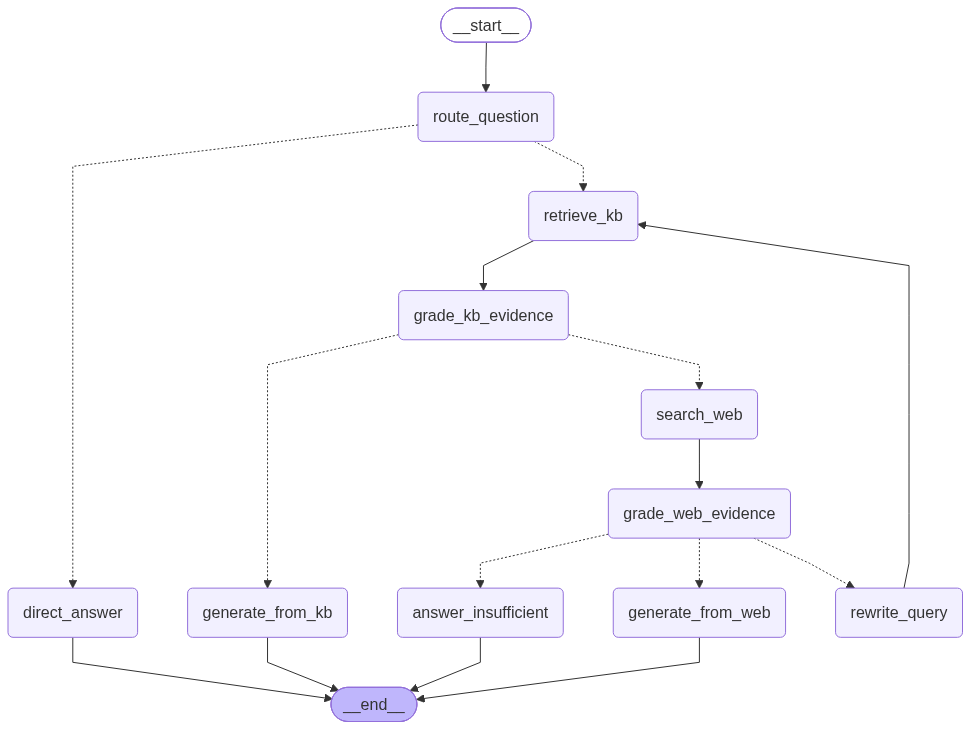

In [26]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization is optional. The graph can still run.")
    print("Reason:", e)

In [27]:
def ask_agent(question: str):
    initial_state = {
    "question": question,
    "current_query": question,
    "kb_docs": [],
    "web_results": "",
    "kb_grade": "",
    "web_grade": "",
    "answer": "",
    "source_used": "",
    "retry_count": 0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("QUESTION:")
    print(question)
    print("\nSOURCE USED:")
    print(result["source_used"])
    print("\nFINAL ANSWER:")
    print(result["answer"])
    print("=" * 90)

    return result

In [28]:
# 24. Demo 1 — Answer from Private KB
result = ask_agent(
    "In Agentic RAG, what happens when retrieved documents are not relevant?"
)

[Router] kb
[KB Retriver] Query:In Agentic RAG, what happens when retrieved documents are not relevant?
[KB Retriver] Retrieved: 4 chunks
[KB Grader] weak
[Tavily Search] Query: In Agentic RAG, what happens when retrieved documents are not relevant?
[Tavily Search] Result characters: 14222
[DEBUG] web_text exists: True
[DEBUG] web_text type: <class 'str'>
[DEBUG] web_text length: 14222
[DEBUG] Returning state update:
{'web_results': 'Tavily answer: When retrieved documents are not relevant in Agentic RAG, the agent uses several strategies to handle the issue. These include relevance scoring to determine if the documents answer the query, followed by re-querying with different search terms if scores fall below a threshold. If retrieval fails, the agent reframes the question and may employ multi-step iteration to chain retrievals. Additionally, fallback strategies such as switching to metadata filtering, keyword search, or broader semantic queries are used when vector search returns spar

In [29]:
# 25. Demo 2 — Web Search Fallback
result = ask_agent(
    "What is Tavily Search and why is it useful for AI agents and RAG workflows?"
)

[Router] kb
[KB Retriver] Query:What is Tavily Search and why is it useful for AI agents and RAG workflows?
[KB Retriver] Retrieved: 4 chunks
[KB Grader] weak
[Tavily Search] Query: What is Tavily Search and why is it useful for AI agents and RAG workflows?
[Tavily Search] Result characters: 13991
[DEBUG] web_text exists: True
[DEBUG] web_text type: <class 'str'>
[DEBUG] web_text length: 13991
[DEBUG] Returning state update:
{'web_results': 'Tavily answer: Tavily is a search API built specifically for AI agents and retrieval-augmented generation (RAG) workflows. It provides a web access layer for AI agents, enabling them to search, extract, and crawl real-time web data in formats optimized for RAG and agent workflows. Unlike traditional search engines, Tavily returns reranked, information-dense snippets that an LLM can reason over directly, offering structured results in JSON, ready for prompts, agents, and RAG pipelines. It is useful for AI agents and RAG applications as it helps brid

In [30]:
# 26. Demo 3 — Direct Answer
result = ask_agent("Hello, how are you?")

[Router] direct

QUESTION:
Hello, how are you?

SOURCE USED:
direct

FINAL ANSWER:
Hi! I'm doing well, thanks. How about you?


In [31]:
# 27. Demo 4 — Ask a Current / External Question
result = ask_agent(
    "What is the current LangChain Tavily package used for Python web search integration?"
)

[Router] kb
[KB Retriver] Query:What is the current LangChain Tavily package used for Python web search integration?
[KB Retriver] Retrieved: 4 chunks
[KB Grader] weak
[Tavily Search] Query: What is the current LangChain Tavily package used for Python web search integration?
[Tavily Search] Result characters: 14956
[DEBUG] web_text exists: True
[DEBUG] web_text type: <class 'str'>
[DEBUG] web_text length: 14956
[DEBUG] Returning state update:
{'web_results': 'Tavily answer: The langchain-tavily package is used for Python web search integration, providing tools that expose Tavily’s Search, Extract, Crawl, and Map endpoints as LangChain tools. It is specifically designed for AI agents to deliver factual and reliable information from trusted sources, enhancing the accuracy and reliability of AI-generated content and reasoning. The package includes functionalities for Search, Extract, Map, and Crawl, and it requires setting up a Tavily API key as an environment variable named `TAVILY_API_K

In [32]:
# 28. Why This Is More Industry-Ready
# This implementation has:

# Private KB first — trusted source first.
# Evidence grading — do not trust weak retrieval.
# Web fallback — use Tavily when KB is insufficient.
# Query rewriting — recover from weak search.
# Retry guard — avoid infinite loops.
# Source tracking — know whether answer came from KB, web or direct path.
# LangGraph control flow — stateful, visible and debuggable workflow.